# Module 8 - Convolutional Neural Network
### Part 2 - Cat and Dog Classification

This notebook demonstrates a CNN using the cat and dog images from Canvas. The input is a 96 by 96 color image. The network gives one output value for each image.

In [1]:
from pathlib import Path
from random import Random
from tempfile import TemporaryDirectory
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
epochs = 10
batch_size = 32
IMAGE_SIZE = (96, 96)
CLASS_NAMES = ("cat", "dog")
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

keras.utils.set_random_seed(SEED)

# Load the Canvas ZIP from A_08.
DATA_SOURCE = Path("data_from_kaggle.zip")
if not DATA_SOURCE.is_file():
    DATA_SOURCE = Path("A_08") / DATA_SOURCE


### Training and Test Images

Loads the images from `data_from_kaggle.zip` and assigns a label of 0 for a cat and 1 for a dog. Each class uses an 80/20 split of its training images. This gives 15,991 images for training and 3,998 for validation. The test folder contains another 5,000 images.

In [2]:
def find_dataset_root(folder):
    candidates = [folder, *folder.rglob("train")]
    for candidate in candidates:
        root = candidate.parent if candidate.name == "train" else candidate
        if (root / "train").is_dir() and (root / "test").is_dir():
            return root
    raise ValueError(f"Could not find paired train and test folders in {folder}.")


if DATA_SOURCE.is_file():
    extracted_data = TemporaryDirectory(prefix="cats-dogs-")
    with ZipFile(DATA_SOURCE) as archive:
        archive.extractall(extracted_data.name)
    dataset_root = find_dataset_root(Path(extracted_data.name))
elif DATA_SOURCE.is_dir():
    dataset_root = find_dataset_root(DATA_SOURCE)
else:
    raise FileNotFoundError(
        f"Canvas dataset missing at {DATA_SOURCE.resolve()}. "
        "Set DATA_SOURCE to the course ZIP or extracted dataset folder."
    )


def labeled_images(folder):
    images = {name: [] for name in CLASS_NAMES}
    for path in sorted(folder.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_SUFFIXES:
            continue
        parent_name = path.parent.name.lower()
        for name in CLASS_NAMES:
            if parent_name == name or path.name.lower().startswith(name):
                images[name].append(path)
                break
    return images


training_pool = labeled_images(dataset_root / "train")
test_images = labeled_images(dataset_root / "test")
splits = {"train": [], "validation": [], "test": []}
rng = Random(SEED)

for label, name in enumerate(CLASS_NAMES):
    paths = training_pool[name]
    if len(paths) < 2 or not test_images[name]:
        raise ValueError(f"Expected at least two training images and one test image for {name}.")
    rng.shuffle(paths)
    cutoff = int(0.8 * len(paths))
    splits["train"].extend((path, label) for path in paths[:cutoff])
    splits["validation"].extend((path, label) for path in paths[cutoff:])
    splits["test"].extend((path, label) for path in test_images[name])

for split, records in splits.items():
    counts = np.bincount([label for _, label in records], minlength=len(CLASS_NAMES))
    print(f"{split:>10}: {len(records):,} total ({counts[0]:,} cats, {counts[1]:,} dogs)")


def decode_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    return tf.image.resize(image, IMAGE_SIZE, antialias=True), label


def make_dataset(records, shuffle=False):
    paths, labels = zip(*records)
    dataset = tf.data.Dataset.from_tensor_slices(
        ([str(path) for path in paths], np.asarray(labels, dtype=np.float32))
    )
    if shuffle:
        dataset = dataset.shuffle(len(records), seed=SEED)
    return (
        dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )


train_dataset = make_dataset(splits["train"], shuffle=True)
val_dataset = make_dataset(splits["validation"])
test_dataset = make_dataset(splits["test"])

     train: 15,991 total (8,000 cats, 7,991 dogs)
validation: 3,998 total (2,000 cats, 1,998 dogs)
      test: 5,000 total (2,500 cats, 2,500 dogs)


### CNN Layers and Training

The CNN uses three convolution layers with 32, 64, and 128 filters. A pooling layer after each one reduces the size of its output. The plots show the training and validation results over 10 epochs.

In [3]:
model = keras.Sequential(
    [
        keras.Input(shape=(*IMAGE_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.RandomFlip("horizontal", seed=SEED),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3, seed=SEED),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="cat_dog_cnn",
)
model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=epochs,
    shuffle=False,
    verbose=2,
)




Model: "cat_dog_cnn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 96, 96, 3)         0         
                                                                 
 random_flip (RandomFlip)    (None, 96, 96, 3)         0         
                                                                 
 conv2d (Conv2D)             (None, 96, 96, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 48, 48, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 48, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 24, 24, 64)        0         
 g2D)                                               

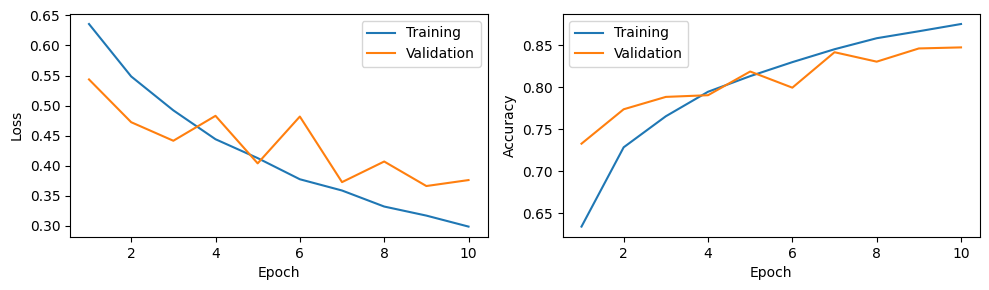

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ("loss", "accuracy")):
    ax.plot(range(1, epochs + 1), history.history[metric], label="Training")
    ax.plot(range(1, epochs + 1), history.history[f"val_{metric}"], label="Validation")
    ax.set(xlabel="Epoch", ylabel=metric.capitalize())
    ax.legend()
fig.tight_layout()
plt.show()

### Test the CNN

Checks the trained CNN against the labels from each set. The model classified 85.04% of the validation images and 86.04% of the test images correctly.

In [5]:
for name, dataset in (("Validation", val_dataset), ("Test", test_dataset)):
    scores = model.evaluate(dataset, verbose=0, return_dict=True)
    print(f"{name} loss: {scores['loss']:.4f} | {name} accuracy: {scores['accuracy']:.2%}")

Validation loss: 0.3761 | Validation accuracy: 84.74%
Test loss: 0.3632 | Test accuracy: 84.90%


### Sample Output

An output of 0.5 or higher gives a prediction of dog. A lower value gives a prediction of cat. The following 10 test images show the actual label and the prediction.

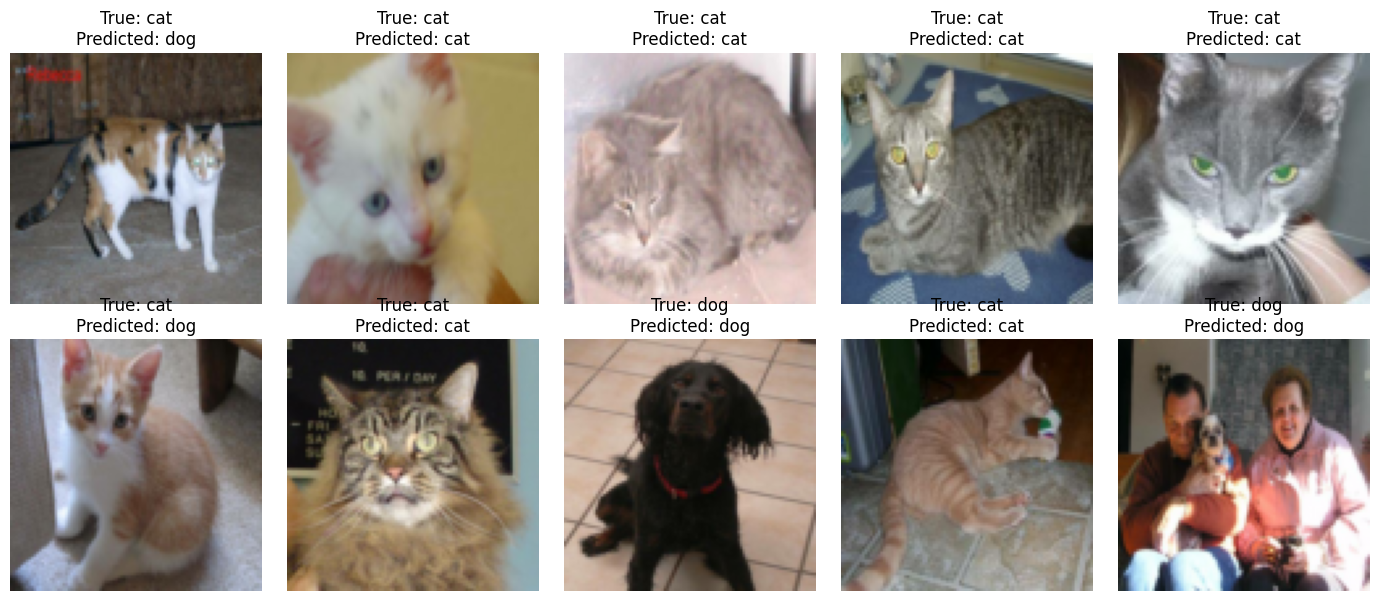

In [6]:
sample_rng = Random(SEED)
examples = sample_rng.sample(splits["test"], k=min(10, len(splits["test"])))
images, actual_labels = next(iter(make_dataset(examples)))
dog_probabilities = model.predict(images, verbose=0).ravel()
predicted_labels = (dog_probabilities >= 0.5).astype(int)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, image, true, predicted in zip(axes.flat, images.numpy(), actual_labels.numpy(), predicted_labels):
    ax.imshow(np.clip(image / 255.0, 0, 1))
    ax.set_title(f"True: {CLASS_NAMES[int(true)]}\nPredicted: {CLASS_NAMES[predicted]}")
fig.tight_layout()
plt.show()